[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/01_basics.ipynb)

*Machine Learning from Scratch · Notebook 1 of 10*

# ML Basics & Data Preparation

What a model learns from, splitting data honestly, baselines, scaling, encoding categories, filling missing values, creating and selecting features, and folds for cross-validation.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Training a model is like studying from past papers: the test set is the real exam you must never peek at.

**What interviewers really test here:** Data leakage, splits, baselines, scaling and encoding.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What is machine learning? *(Basics)*
- [ ] 2. Train, validation and test sets *(Basics)*
- [ ] 3. Choosing the right kind of model *(Basics)*
- [ ] 4. Scaling features *(Core)*
- [ ] 5. Encoding categories and filling missing values *(Core)*
- [ ] 6. Leakage, worked by hand *(Core)*
- [ ] 7. Imbalanced classes *(Core)*
- [ ] 8. Feature engineering, selection and pipelines *(Advanced)*
- [ ] 9. A complete small project, start to finish *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Types of machine learning

| Type | Learns from | Goal | Algorithms |
| --- | --- | --- | --- |
| Supervised — regression | (X, numeric y) | predict a number | linear regression, trees, gradient boosting |
| Supervised — classification | (X, class y) | predict a category | logistic regression, k-NN, SVM, random forest |
| Unsupervised | X only | find structure | k-means, DBSCAN, PCA |
| Semi-/self-supervised | few labels / labels made from the data | use unlabelled data | pre-training of LLMs |
| Reinforcement learning | rewards from actions | learn a policy | Q-learning, policy gradients, RLHF |

### The ML workflow

1. Define the problem and the metric that matters (and a baseline).
2. Collect and explore data (EDA): types, missing values, distributions, target balance, leakage.
3. Split: train / validation (or cross-validation) / test — before any fitting.
4. Preprocess and engineer features — fitted on training data only, inside a pipeline.
5. Train candidate models; tune hyper-parameters with cross-validation.
6. Evaluate once on the test set; analyse errors.
7. Deploy, monitor for **data drift**, retrain.



**Parameters** are learned from data (weights); **hyper-parameters** are chosen by you (learning rate, tree depth, k).

### Preprocessing reference

| Problem | Technique | sklearn |
| --- | --- | --- |
| Different scales | standardise / min-max / robust | StandardScaler, MinMaxScaler, RobustScaler |
| Skewed numbers | log, Box-Cox, Yeo-Johnson | FunctionTransformer, PowerTransformer |
| Unordered categories | one-hot | OneHotEncoder(handle\_unknown="ignore") |
| Ordered categories | ordinal | OrdinalEncoder(categories=[…]) |
| High-cardinality categories | target / frequency encoding, hashing | TargetEncoder |
| Missing values | mean / median / mode / KNN / indicator | SimpleImputer, KNNImputer, MissingIndicator |
| Non-linear effects | polynomial features, binning, splines | PolynomialFeatures, KBinsDiscretizer, SplineTransformer |
| Mixed column types | different steps per column | ColumnTransformer |

### Data leakage

**Leakage** is when information that would not be available at prediction time sneaks into training, giving great validation scores and poor real results. Common causes:




- Fitting scalers, imputers or feature selection on the full dataset before splitting.
- Features derived from the target (e.g. "refund issued" when predicting fraud).
- Duplicate or near-duplicate rows across train and test.
- Random splits of time-series data (the model sees the future) — use time-based splits.
- Rows from the same patient/user in both train and test — use GroupKFold.

### Common beginner mistakes

| Mistake | Why it hurts | Do this instead |
| --- | --- | --- |
| Judging a model on its training data | rewards memorising | score on held-out data |
| Skipping the baseline | you can't tell if it learned anything | compare with a dummy model |
| Preprocessing before splitting | leakage inflates the score | put preprocessing in a pipeline |
| Only reporting accuracy on imbalanced data | hides total failure on the rare class | recall, precision, PR-AUC |
| Tuning repeatedly against the test set | the test score becomes optimistic | tune with CV, test once |
| Trying fancy models first | harder to debug, often no better | simple model first, then add complexity |

---
# Part 2: Lessons, step by step

## Lesson 1: What is machine learning?

*Level: Basics*

Normal programming: you write the rules, the computer applies them. **Machine learning**: you give the computer **examples** and it works out the rules itself.




- **Features** X: the inputs (house size, rooms, age). One row per example, one column per feature.
- **Target / label** y: what we want to predict (price).
- **Model**: a function with adjustable numbers (**parameters**) that maps X to a prediction ŷ.
- **Training**: adjusting the parameters so ŷ is close to y on known examples.



| Type | Has labels? | Examples |
| --- | --- | --- |
| **Regression** (supervised) | yes, numbers | price, temperature, demand |
| **Classification** (supervised) | yes, categories | spam / not spam, disease, digit 0–9 |
| **Clustering** (unsupervised) | no | customer segments |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

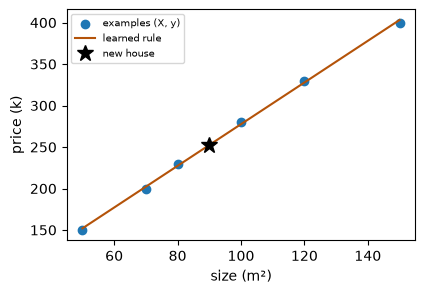

In [2]:
def first_model():
    size = np.array([50, 70, 80, 100, 120, 150])
    price = np.array([150, 200, 230, 280, 330, 400])
    slope, intercept = np.polyfit(size, price, 1)
    prediction_for_90 = slope * 90 + intercept
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.scatter(size, price, label="examples (X, y)")
    ax.plot(size, slope * size + intercept, color="#b45309", label="learned rule")
    ax.plot(90, prediction_for_90, "k*", markersize=12, label="new house")
    ax.set_xlabel("size (m²)")
    ax.set_ylabel("price (k)")
    ax.legend(fontsize=7)


first_model()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 2: Train, validation and test sets

*Level: Basics*

A model can memorise its training data and still fail on new data. So we always hold some data back:




- **Training set** (~60–80%): the model learns from it.
- **Validation set** (or cross-validation): used to choose settings and compare models.
- **Test set** (~20%): touched **once**, at the very end, to estimate real-world performance.



Always compare against a **baseline** — predict the most common class, or the average value. A 95% accurate model is useless if 95% of emails aren't spam anyway.



In sklearn: `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)`. `stratify` keeps class proportions the same in both parts.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
from sklearn.model_selection import train_test_split


def split_demo():
    X = np.arange(20).reshape(-1, 1)
    y = np.array([0] * 14 + [1] * 6)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
    train_share_of_1 = y_train.mean()
    test_share_of_1 = y_test.mean()


split_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q19](#q19), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 3: Choosing the right kind of model

*Level: Basics*

Before any code, turn the question into a machine-learning task. Ask three things:




1. **Do I have the answers for past examples?** Yes means supervised learning. No means unsupervised.
2. **What kind of answer do I want?** A number means regression. A category means classification.
3. **How will I know it worked?** Pick the metric and the baseline before training.



| Question | Task | First model to try | Baseline |
| --- | --- | --- | --- |
| What price will this flat sell for? | regression | linear regression, then boosting | the average price |
| Is this transaction fraud? | binary classification | logistic regression, then boosting | "never fraud" |
| Which topic is this article about? | multi-class classification | Naive Bayes or logistic regression | the most common topic |
| Which customers are alike? | clustering | k-means | none: judge usefulness |



#### A checklist for every dataset




- How many rows and columns? What does one row mean?
- Which columns are numbers, categories, dates or free text?
- How many values are missing, and is that pattern meaningful?
- Is the target balanced? Are there duplicates or impossible values?
- Would each column really be known at prediction time? If not, it leaks.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def explore_first():
    df = pd.DataFrame({"size": [50, 70, None, 100, 120, 900], "city": ["Pune", "Delhi", "Pune", None, "Pune", "Delhi"], "price": [150, 200, 230, 280, 330, 2500]})
    shape = df.shape
    missing = df.isna().sum()
    summary = df["size"].describe()
    city_counts = df["city"].value_counts()
    suspicious_rows = df[df["size"] > 500]


explore_first()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 4: Scaling features

*Level: Core*

Many algorithms (k-NN, SVM, neural networks, gradient descent, PCA) treat features by their raw numbers. If income is in the tens of thousands and age in tens, income dominates. **Scaling** puts features on comparable ranges:



| Scaler | Formula | When |
| --- | --- | --- |
| StandardScaler | (x − mean)/std | default choice |
| MinMaxScaler | (x − min)/(max − min) | need [0, 1] (images, NN inputs) |
| RobustScaler | (x − median)/IQR | outliers present |
| log1p | log(1 + x) | long right tail (income, counts) |



**Golden rule**: fit the scaler on the **training** data only, then apply the same numbers to the test data. Fitting on all the data leaks test information into training (**data leakage**). Trees don't need scaling.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

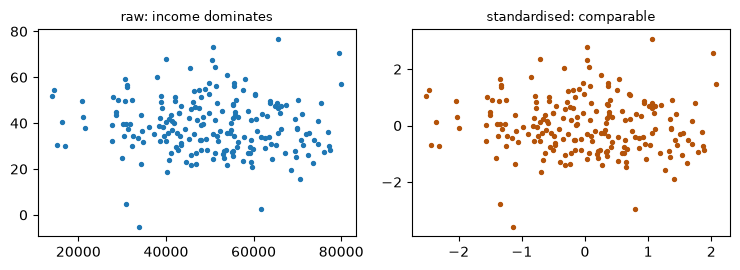

In [5]:
from sklearn.preprocessing import StandardScaler


def scaling_demo():
    rng = np.random.default_rng(0)
    income = rng.normal(50000, 15000, 200)
    age = rng.normal(40, 12, 200)
    scaled = StandardScaler().fit_transform(np.column_stack([income, age]))
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.8))
    left.scatter(income, age, s=8)
    left.set_title("raw: income dominates", fontsize=9)
    right.scatter(scaled[:, 0], scaled[:, 1], s=8, color="#b45309")
    right.set_title("standardised: comparable", fontsize=9)
    fig.tight_layout()


scaling_demo()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q4](#q4), [Q14](#q14), [Q10](#q10), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 5: Encoding categories and filling missing values

*Level: Core*

Models need numbers. For categorical columns:




- **One-hot encoding**: one 0/1 column per category (colour → is\_red, is\_green, is\_blue). Safe default for unordered categories.
- **Ordinal encoding**: low → 0, medium → 1, high → 2 — only when the order is real.
- **Label encoding**: for the **target** of a classifier.



**Missing values**: drop rows if very few, otherwise **impute** — mean or median for numbers, most frequent for categories (learned on train only!). Adding a "was missing" flag column can help, because missingness itself can be informative.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def encode_demo():
    colours = np.array(["red", "green", "blue", "green"])
    categories = np.unique(colours)
    one_hot = (colours[:, None] == categories).astype(int)
    sizes = ["low", "high", "medium"]
    order = ["low", "medium", "high"]
    ordinal = [order.index(s) for s in sizes]


encode_demo()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q7](#q7), [Q6](#q6), [Q8](#q8), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 6: Leakage, worked by hand

*Level: Core*

**Idea:** a model must only learn from what it would have at prediction time. Fitting a scaler on the full data quietly breaks this.



#### Worked example



Training values are 1, 2, 3 and the only test value is 10.



|   | Correct: fit on train | Leaky: fit on all data |
| --- | --- | --- |
| Mean | 2 | 4 |
| Standard deviation | 0.816 | 3.536 |
| Scaled test value | (10 − 2) / 0.816 = **9.80** | (10 − 4) / 3.536 = **1.70** |



The correct version says plainly that 10 is far outside anything seen in training. The leaky version makes it look ordinary, because the outlier helped set the scale. The model was evaluated on data that had already shaped its inputs, so the score can't be trusted.



#### Common mistakes




- Calling `fit_transform` on the test set. Use `transform`.
- Selecting features, or filling missing values, before splitting.
- A column recorded after the outcome, such as "days in hospital" when predicting admission.
- Shuffling time-series data, which lets the model see the future.



**Warning sign:** a score that looks too good. Check which feature is doing the work.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def leakage_numbers():
    train = np.array([1.0, 2.0, 3.0])
    test_value = 10.0
    correct = (test_value - train.mean()) / train.std()
    everything = np.append(train, test_value)
    leaky = (test_value - everything.mean()) / everything.std()


leakage_numbers()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 7: Imbalanced classes

*Level: Core*

**Idea:** when one class is rare, a model can score highly by ignoring it. If 95 of 100 emails are fine, predicting "fine" every time is 95% accurate and catches nothing.



#### Worked example: balanced class weights



weight = n\_samples / (n\_classes × count of that class)



| Class | Count | Weight |
| --- | --- | --- |
| Normal | 95 | 100 / (2 × 95) = 0.526 |
| Fraud | 5 | 100 / (2 × 5) = 10 |



Each fraud row now counts 19 times as much as a normal row, so both classes contribute equally to the loss.



#### What you can do, in the order to try it




1. Use a metric that sees the rare class: recall, precision, F1 or PR-AUC.
2. Use `stratify=y` when splitting, so every part contains the rare class.
3. Set `class_weight="balanced"`.
4. Move the decision threshold instead of staying at 0.5.
5. Resample the **training** data only. Oversampling before the split copies rows into the test set, which is leakage.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def imbalance_trap():
    y_true = np.array([0] * 95 + [1] * 5)
    always_normal = np.zeros(100, dtype=int)
    accuracy = (always_normal == y_true).mean()
    frauds_caught = always_normal[y_true == 1].sum()
    weight_normal = 100 / (2 * 95)
    weight_fraud = 100 / (2 * 5)
    balance = (95 * weight_normal, 5 * weight_fraud)


imbalance_trap()

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 8: Feature engineering, selection and pipelines

*Level: Advanced*

Better features usually beat fancier models:




- **Create**: polynomial terms (x², x₁x₂) let linear models bend; ratios (price per m²); dates → day of week, month; text → word counts; bins for non-linear effects.
- **Select**: drop near-constant columns, keep the k most related to the target, or let regularisation (Lasso) or tree importances decide.
- **Imbalanced classes**: `class_weight="balanced"` makes rare-class mistakes cost more.



A **Pipeline** chains preprocessing and the model into one object: `make_pipeline(StandardScaler(), LogisticRegression())`. It fits every step on training data only, so cross-validation stays leak-free, and one call deploys the whole thing.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

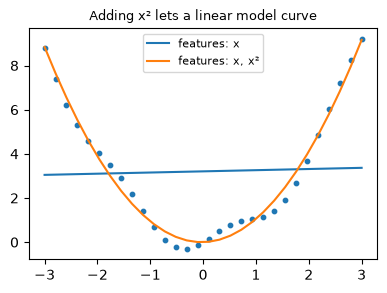

In [9]:
def poly_demo():
    x = np.linspace(-3, 3, 30)
    y = x ** 2 + np.sin(3 * x) * 0.5
    straight = np.polyval(np.polyfit(x, y, 1), x)
    curved = np.polyval(np.polyfit(x, y, 2), x)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.scatter(x, y, s=10)
    ax.plot(x, straight, label="features: x")
    ax.plot(x, curved, label="features: x, x²")
    ax.legend(fontsize=8)
    ax.set_title("Adding x² lets a linear model curve", fontsize=9)


poly_demo()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q16](#q16), [Q11](#q11), [Q18](#q18), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 9: A complete small project, start to finish

*Level: Advanced*

Here is every step on one small dataset. The demo below runs all of them.




1. **Define:** predict the flat price; measure with mean absolute error (MAE).
2. **Split first:** hold out a test set before looking closely at anything.
3. **Baseline:** always predict the training average, and record its error.
4. **Prepare:** fill missing sizes, scale numbers and one-hot encode the city, all inside one pipeline.
5. **Train and compare:** the model must beat the baseline.
6. **Test once:** report that score, and don't tune after seeing it.
7. **Inspect errors:** which rows are worst, and why?



Real projects spend most of their time on steps 1–4 and step 7.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

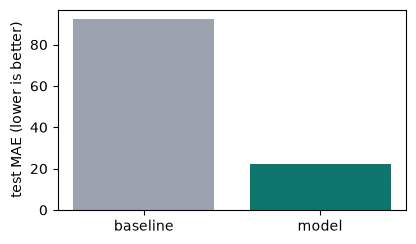

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


def whole_project():
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import mean_absolute_error
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import OneHotEncoder
    rng = np.random.default_rng(0)
    size = rng.uniform(40, 150, 60)
    city = rng.choice(["Pune", "Delhi"], 60)
    price = 3 * size + np.where(city == "Delhi", 60, 0) + rng.normal(0, 15, 60)
    df = pd.DataFrame({"size": size, "city": city})
    df.loc[::10, "size"] = np.nan
    X_train, X_test, y_train, y_test = train_test_split(df, price, test_size=0.25, random_state=0)
    baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
    prep = ColumnTransformer([("num", make_pipeline(SimpleImputer(), StandardScaler()), ["size"]), ("cat", OneHotEncoder(), ["city"])])
    model = make_pipeline(prep, LinearRegression()).fit(X_train, y_train)
    model_mae = mean_absolute_error(y_test, model.predict(X_test))
    fig, ax = plt.subplots(figsize=(4.5, 2.6))
    ax.bar(["baseline", "model"], [baseline_mae, model_mae], color=["#9ca3af", "#0f766e"])
    ax.set_ylabel("test MAE (lower is better)")


whole_project()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q1](#q1), [Q3](#q3). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [11]:
from sklearn.model_selection import train_test_split, KFold

import math

from sklearn.dummy import DummyClassifier, DummyRegressor

from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, LabelEncoder,
                                   OrdinalEncoder, PolynomialFeatures, KBinsDiscretizer, FunctionTransformer, Normalizer)

from sklearn.impute import SimpleImputer

from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression


<a id="q1"></a>
### Q1. Train / Test Split Without Shuffling

🟢 Warm-up · *Holding data back*

Split X into (train, test) with the last test\_size fraction (rounded up) as the test set, keeping the order.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], test_size = 0.25` → `([[1], [2], [3], [4], [5], [6]], [[7], [8]])`
- `X = [[1, 2], [3, 4], [5, 6]], test_size = 0.5` → `([[1, 2]], [[3, 4], [5, 6]])`

In [ ]:
def split(X, test_size):
    """
    Split X into (train, test) with the last test_size fraction (rounded up) as
    the test set, keeping the order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(split, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], 0.25), ([[1], [2], [3], [4], [5], [6]], [[7], [8]])),
    (([[1, 2], [3, 4], [5, 6]], 0.5), ([[1, 2]], [[3, 4], [5, 6]])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count how many rows go to the test set (round up), then slice.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`train_test_split(X, test_size=…, shuffle=False)`. In real projects keep shuffle on and set random\_state.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count how many rows go to the test set (round up), then slice.

```python
def split(X, test_size):
    n_test = math.ceil(len(X) * test_size)
    n_train = len(X) - n_test
    return (X[:n_train], X[n_train:])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `train_test_split(X, test_size=…, shuffle=False)`. In real projects keep shuffle on and set random\_state.

```python
def split(X, test_size):
    train, test = train_test_split(X, test_size=test_size, shuffle=False)
    return (train, test)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count how many rows go to the test set (round up), then slice. That costs O(n) time and O(n) space."

"I can do better: `train_test_split(X, test_size=…, shuffle=False)`. In real projects keep shuffle on and set random\_state. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/train-test-split-without-shuffling)

<a id="q2"></a>
### Q2. Majority-Class Baseline

🟢 Warm-up · *The score to beat*

Always predict the most common training label (ties → smallest label). Return the accuracy on the test labels, rounded to 4 decimals.

**Examples**

- `y_train = ['a', 'a', 'b', 'a', 'c'], y_test = ['a', 'b', 'a']` → `0.6667`
- `y_train = [1, 0, 1, 0], y_test = [0, 0, 1]` → `0.6667`

In [ ]:
def baseline_accuracy(y_train, y_test):
    """
    Always predict the most common training label (ties → smallest label).
    Return the accuracy on the test labels, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(baseline_accuracy, [
    ((['a', 'a', 'b', 'a', 'c'], ['a', 'b', 'a']), 0.6667),
    (([1, 0, 1, 0], [0, 0, 1]), 0.6667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count labels in a dictionary, pick the winner, compare with every test label.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DummyClassifier(strategy='most_frequent')` — every model must beat this.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count labels in a dictionary, pick the winner, compare with every test label.

```python
def baseline_accuracy(y_train, y_test):
    counts = {}
    for label in y_train:
        counts[label] = counts.get(label, 0) + 1
    best = max(counts.values())
    guess = min(label for label, c in counts.items() if c == best)
    correct = sum(1 for label in y_test if label == guess)
    return round(correct / len(y_test), 4)
```

**Cost:** O(n + m) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DummyClassifier(strategy='most_frequent')` — every model must beat this.

```python
def baseline_accuracy(y_train, y_test):
    model = DummyClassifier(strategy="most_frequent")
    model.fit(np.zeros((len(y_train), 1)), y_train)
    return round(model.score(np.zeros((len(y_test), 1)), y_test), 4)
```

**Cost:** O(n + m) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count labels in a dictionary, pick the winner, compare with every test label. That costs O(n + m) time and O(k) space."

"I can do better: `DummyClassifier(strategy='most_frequent')` — every model must beat this. That's O(n + m) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/majority-class-baseline)

<a id="q3"></a>
### Q3. Mean Baseline for Regression

🟢 Warm-up · *Predict the average*

Always predict the mean of the training targets. Return the mean squared error on the test targets, rounded to 4 decimals.

**Examples**

- `y_train = [10, 20, 30], y_test = [15, 25]` → `25.0`
- `y_train = [2, 4, 6, 8], y_test = [5, 5, 5]` → `0.0`

In [ ]:
def baseline_mse(y_train, y_test):
    """
    Always predict the mean of the training targets. Return the mean squared
    error on the test targets, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(baseline_mse, [
    (([10, 20, 30], [15, 25]), 25.0),
    (([2, 4, 6, 8], [5, 5, 5]), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average the training targets, then average the squared errors on the test set.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DummyRegressor()` and `mean_squared_error`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Average the training targets, then average the squared errors on the test set.

```python
def baseline_mse(y_train, y_test):
    guess = sum(y_train) / len(y_train)
    total = 0
    for y in y_test:
        total += (y - guess) ** 2
    return round(total / len(y_test), 4)
```

**Cost:** O(n + m) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DummyRegressor()` and `mean_squared_error`.

```python
def baseline_mse(y_train, y_test):
    from sklearn.metrics import mean_squared_error
    model = DummyRegressor().fit(np.zeros((len(y_train), 1)), y_train)
    pred = model.predict(np.zeros((len(y_test), 1)))
    return round(mean_squared_error(y_test, pred), 4)
```

**Cost:** O(n + m) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average the training targets, then average the squared errors on the test set. That costs O(n + m) time and O(1) space."

"I can do better: `DummyRegressor()` and `mean_squared_error`. That's O(n + m) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/mean-baseline-for-regression)

<a id="q4"></a>
### Q4. Min-Max Scaling

🟢 Warm-up · *Squeeze into [0, 1]*

Learn each column's min and max from the training rows, then scale the test rows to (x − min)/(max − min). Round to 4 decimals.

**Examples**

- `train = [[0, 100], [10, 200]], test = [[5, 150], [20, 100]]` → `[[0.5, 0.5], [2.0, 0.0]]`

In [ ]:
def min_max(train, test):
    """
    Learn each column's min and max from the training rows, then scale the test
    rows to (x − min)/(max − min). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(min_max, [
    (([[0, 100], [10, 200]], [[5, 150], [20, 100]]), [[0.5, 0.5], [2.0, 0.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Min and max per column with loops, then the formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`MinMaxScaler().fit(train).transform(test)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Min and max per column with loops, then the formula.

```python
def min_max(train, test):
    d = len(train[0])
    lo = [min(r[j] for r in train) for j in range(d)]
    hi = [max(r[j] for r in train) for j in range(d)]
    return [[round((r[j] - lo[j]) / (hi[j] - lo[j]), 4) for j in range(d)] for r in test]
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `MinMaxScaler().fit(train).transform(test)`.

```python
def min_max(train, test):
    return MinMaxScaler().fit(train).transform(test).round(4)
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Min and max per column with loops, then the formula. That costs O(n·d) time and O(d) space."

"I can do better: `MinMaxScaler().fit(train).transform(test)`. That's O(n·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/min-max-scaling)

<a id="q5"></a>
### Q5. One-Hot Encoding

🟢 Warm-up · *Categories → 0/1 columns*

Turn a list of categories into rows of 0/1 indicators, columns in sorted category order.

**Examples**

- `values = ['red', 'green', 'blue', 'green']` → `[[0.0, 0.0, 1.0], [0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]`
- `values = ['b', 'a']` → `[[0.0, 1.0], [1.0, 0.0]]`

In [ ]:
def one_hot(values):
    """
    Turn a list of categories into rows of 0/1 indicators, columns in sorted
    category order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(one_hot, [
    ((['red', 'green', 'blue', 'green'],), [[0.0, 0.0, 1.0], [0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]),
    ((['b', 'a'],), [[0.0, 1.0], [1.0, 0.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sorted unique categories give the columns; each row has a single 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`OneHotEncoder(sparse_output=False)` on a one-column matrix.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sorted unique categories give the columns; each row has a single 1.

```python
def one_hot(values):
    cats = sorted(set(values))
    rows = []
    for v in values:
        rows.append([1.0 if v == c else 0.0 for c in cats])
    return rows
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `OneHotEncoder(sparse_output=False)` on a one-column matrix.

```python
def one_hot(values):
    enc = OneHotEncoder(sparse_output=False)
    return enc.fit_transform(np.array(values).reshape(-1, 1))
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sorted unique categories give the columns; each row has a single 1. That costs O(n·k) time and O(n·k) space."

"I can do better: `OneHotEncoder(sparse_output=False)` on a one-column matrix. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/one-hot-encoding)

<a id="q6"></a>
### Q6. Label Encoding

🟢 Warm-up · *Classes → 0, 1, 2, …*

Map each label to its position in the sorted list of distinct labels.

**Examples**

- `labels = ['cat', 'dog', 'cat', 'bird']` → `[1, 2, 1, 0]`
- `labels = [30, 10, 20, 10]` → `[2, 0, 1, 0]`

In [ ]:
def label_encode(labels):
    """
    Map each label to its position in the sorted list of distinct labels.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(label_encode, [
    ((['cat', 'dog', 'cat', 'bird'],), [1, 2, 1, 0]),
    (([30, 10, 20, 10],), [2, 0, 1, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build a dict from sorted unique labels to positions, look each one up.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LabelEncoder().fit_transform(y)` (meant for targets, not features).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Build a dict from sorted unique labels to positions, look each one up.

```python
def label_encode(labels):
    lookup = {}
    for i, lab in enumerate(sorted(set(labels))):
        lookup[lab] = i
    return [lookup[lab] for lab in labels]
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LabelEncoder().fit_transform(y)` (meant for targets, not features).

```python
def label_encode(labels):
    return LabelEncoder().fit_transform(labels)
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build a dict from sorted unique labels to positions, look each one up. That costs O(n log n) time and O(k) space."

"I can do better: `LabelEncoder().fit_transform(y)` (meant for targets, not features). That's O(n log n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/label-encoding)

<a id="q7"></a>
### Q7. Ordinal Encoding With an Order

🟢 Warm-up · *Low &lt; Medium &lt; High*

Encode each value by its position in the given order list.

**Examples**

- `values = ['low', 'high', 'medium', 'low'], order = ['low', 'medium', 'high']` → `[0.0, 2.0, 1.0, 0.0]`
- `values = ['S', 'XL'], order = ['S', 'M', 'L', 'XL']` → `[0.0, 3.0]`

In [ ]:
def ordinal(values, order):
    """
    Encode each value by its position in the given order list.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ordinal, [
    ((['low', 'high', 'medium', 'low'], ['low', 'medium', 'high']), [0.0, 2.0, 1.0, 0.0]),
    ((['S', 'XL'], ['S', 'M', 'L', 'XL']), [0.0, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`order.index(value)` for each value.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`OrdinalEncoder(categories=[order])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `order.index(value)` for each value.

```python
def ordinal(values, order):
    return [float(order.index(v)) for v in values]
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `OrdinalEncoder(categories=[order])`.

```python
def ordinal(values, order):
    enc = OrdinalEncoder(categories=[order])
    return enc.fit_transform(np.array(values).reshape(-1, 1)).ravel()
```

**Cost:** O(n log k) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `order.index(value)` for each value. That costs O(n·k) time and O(n) space."

"I can do better: `OrdinalEncoder(categories=[order])`. That's O(n log k) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/ordinal-encoding-with-an-order)

<a id="q8"></a>
### Q8. Fill Missing Values With the Mean

🟢 Warm-up · *Imputation*

None marks a missing value. Replace it with its column's mean (computed from the values present). Round to 4 decimals.

**Examples**

- `rows = [[1, None], [3, 4], [None, 8]]` → `[[1.0, 6.0], [3.0, 4.0], [2.0, 8.0]]`
- `rows = [[None], [2], [4]]` → `[[3.0], [2.0], [4.0]]`

In [ ]:
def impute_mean(rows):
    """
    None marks a missing value. Replace it with its column's mean (computed from
    the values present). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(impute_mean, [
    (([[1, None], [3, 4], [None, 8]],), [[1.0, 6.0], [3.0, 4.0], [2.0, 8.0]]),
    (([[None], [2], [4]],), [[3.0], [2.0], [4.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Per column, average the non-missing values, then fill the gaps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`SimpleImputer(strategy='mean')` (NaN marks missing).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Per column, average the non-missing values, then fill the gaps.

```python
def impute_mean(rows):
    d = len(rows[0])
    means = []
    for j in range(d):
        present = [r[j] for r in rows if r[j] is not None]
        means.append(sum(present) / len(present))
    return [[round(r[j] if r[j] is not None else means[j], 4) for j in range(d)] for r in rows]
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `SimpleImputer(strategy='mean')` (NaN marks missing).

```python
def impute_mean(rows):
    X = np.array([[np.nan if v is None else v for v in r] for r in rows], dtype=float)
    return SimpleImputer(strategy="mean").fit_transform(X).round(4)
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Per column, average the non-missing values, then fill the gaps. That costs O(n·d) time and O(d) space."

"I can do better: `SimpleImputer(strategy='mean')` (NaN marks missing). That's O(n·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/fill-missing-values-with-the-mean)

<a id="q9"></a>
### Q9. Fill Missing Categories With the Mode

🟢 Warm-up · *Most frequent value*

Replace None with the most common category (ties → alphabetically first).

**Examples**

- `values = ['a', None, 'b', 'a', None]` → `['a', 'a', 'b', 'a', 'a']`
- `values = ['x', 'y', None]` → `['x', 'y', 'x']`

In [ ]:
def impute_mode(values):
    """
    Replace None with the most common category (ties → alphabetically first).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(impute_mode, [
    ((['a', None, 'b', 'a', None],), ['a', 'a', 'b', 'a', 'a']),
    ((['x', 'y', None],), ['x', 'y', 'x']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count the present values, pick the winner, fill.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`SimpleImputer(strategy='most_frequent')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count the present values, pick the winner, fill.

```python
def impute_mode(values):
    counts = {}
    for v in values:
        if v is not None:
            counts[v] = counts.get(v, 0) + 1
    best = max(counts.values())
    mode = min(v for v, c in counts.items() if c == best)
    return [mode if v is None else v for v in values]
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `SimpleImputer(strategy='most_frequent')`.

```python
def impute_mode(values):
    X = np.array(values, dtype=object).reshape(-1, 1)
    imp = SimpleImputer(strategy="most_frequent", missing_values=None)
    return imp.fit_transform(X).ravel().tolist()
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count the present values, pick the winner, fill. That costs O(n) time and O(k) space."

"I can do better: `SimpleImputer(strategy='most_frequent')`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/fill-missing-categories-with-the-mode)

<a id="q10"></a>
### Q10. Log Transform a Skewed Feature

🟢 Warm-up · *log(1 + x)*

Return log(1 + x) for each value, rounded to 4 decimals — tames long right tails like incomes.

**Examples**

- `values = [0, 9, 99, 999]` → `[0.0, 2.3026, 4.6052, 6.9078]`

In [ ]:
def log_transform(values):
    """
    Return log(1 + x) for each value, rounded to 4 decimals — tames long right
    tails like incomes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(log_transform, [
    (([0, 9, 99, 999],), [0.0, 2.3026, 4.6052, 6.9078]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`math.log1p` in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`FunctionTransformer(np.log1p)` — a transformer you can put in a pipeline.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `math.log1p` in a loop.

```python
def log_transform(values):
    return [round(math.log1p(x), 4) for x in values]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `FunctionTransformer(np.log1p)` — a transformer you can put in a pipeline.

```python
def log_transform(values):
    ft = FunctionTransformer(np.log1p)
    return ft.fit_transform(np.array(values, dtype=float).reshape(-1, 1)).ravel().round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `math.log1p` in a loop. That costs O(n) time and O(n) space."

"I can do better: `FunctionTransformer(np.log1p)` — a transformer you can put in a pipeline. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/log-transform-a-skewed-feature)

<a id="q11"></a>
### Q11. Drop Near-Constant Features

🟢 Warm-up · *Variance threshold*

Return the indices of columns whose (population) variance is greater than threshold.

**Examples**

- `X = [[1, 5, 0], [1, 6, 0], [1, 7, 1]], threshold = 0.1` → `[1, 2]`
- `X = [[2, 2], [2, 2]], threshold = 0.0` → `[]`

In [ ]:
def keep_varied(X, threshold):
    """
    Return the indices of columns whose (population) variance is greater than
    threshold.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(keep_varied, [
    (([[1, 5, 0], [1, 6, 0], [1, 7, 1]], 0.1), [1, 2]),
    (([[2, 2], [2, 2]], 0.0), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Variance of each column with loops; keep the ones above the threshold.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`VarianceThreshold(threshold).fit(X).get_support(indices=True)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Variance of each column with loops; keep the ones above the threshold.

```python
def keep_varied(X, threshold):
    keep = []
    for j in range(len(X[0])):
        col = [r[j] for r in X]
        mean = sum(col) / len(col)
        var = sum((v - mean) ** 2 for v in col) / len(col)
        if var > threshold:
            keep.append(j)
    return keep
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `VarianceThreshold(threshold).fit(X).get_support(indices=True)`.

```python
def keep_varied(X, threshold):
    try:
        return VarianceThreshold(threshold).fit(X).get_support(indices=True)
    except ValueError:  # every feature removed
        return []
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Variance of each column with loops; keep the ones above the threshold. That costs O(n·d) time and O(d) space."

"I can do better: `VarianceThreshold(threshold).fit(X).get_support(indices=True)`. That's O(n·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/drop-near-constant-features)

<a id="q12"></a>
### Q12. Normalise Each Row

🟢 Warm-up · *Unit-length samples*

Divide each row by its Euclidean length (useful for text vectors). Round to 4 decimals.

**Examples**

- `rows = [[3, 4], [1, 0], [1, 1]]` → `[[0.6, 0.8], [1.0, 0.0], [0.7071, 0.7071]]`

In [ ]:
def normalise_rows(rows):
    """
    Divide each row by its Euclidean length (useful for text vectors). Round to
    4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(normalise_rows, [
    (([[3, 4], [1, 0], [1, 1]],), [[0.6, 0.8], [1.0, 0.0], [0.7071, 0.7071]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Length of each row by hand, then divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Normalizer()` (works row by row, unlike scalers).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Length of each row by hand, then divide.

```python
def normalise_rows(rows):
    out = []
    for r in rows:
        length = math.sqrt(sum(v * v for v in r))
        out.append([round(v / length, 4) for v in r])
    return out
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `Normalizer()` (works row by row, unlike scalers).

```python
def normalise_rows(rows):
    return Normalizer().fit_transform(rows).round(4)
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Length of each row by hand, then divide. That costs O(n·d) time and O(n·d) space."

"I can do better: `Normalizer()` (works row by row, unlike scalers). That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/normalise-each-row)

<a id="q13"></a>
### Q13. Standard Scaling (Fit on Train Only)

🟡 Interview standard · *z = (x − mean) / std*

Learn each column's mean and standard deviation (population) from the training rows, then scale the test rows. Round to 4 decimals.

**Examples**

- `train = [[1, 10], [2, 20], [3, 30]], test = [[2, 40], [4, 10]]` → `[[0.0, 2.4495], [2.4495, -1.2247]]`

In [ ]:
def standard_scale(train, test):
    """
    Learn each column's mean and standard deviation (population) from the
    training rows, then scale the test rows. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(standard_scale, [
    (([[1, 10], [2, 20], [3, 30]], [[2, 40], [4, 10]]), [[0.0, 2.4495], [2.4495, -1.2247]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Column means and stds with loops, then (x − mean)/std for each test value.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`StandardScaler().fit(train).transform(test)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Column means and stds with loops, then (x − mean)/std for each test value.

```python
def standard_scale(train, test):
    d = len(train[0])
    means = [sum(r[j] for r in train) / len(train) for j in range(d)]
    stds = [math.sqrt(sum((r[j] - means[j]) ** 2 for r in train) / len(train)) for j in range(d)]
    return [[round((r[j] - means[j]) / stds[j], 4) for j in range(d)] for r in test]
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `StandardScaler().fit(train).transform(test)`.

```python
def standard_scale(train, test):
    scaler = StandardScaler().fit(train)
    return scaler.transform(test).round(4)
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Column means and stds with loops, then (x − mean)/std for each test value. That costs O(n·d) time and O(d) space."

"I can do better: `StandardScaler().fit(train).transform(test)`. That's O(n·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/standard-scaling-fit-on-train-only)

<a id="q14"></a>
### Q14. Robust Scaling

🟡 Interview standard · *Median and IQR resist outliers*

Scale one column as (x − median) / IQR, where the IQR (Q3 − Q1) uses linear interpolation. Round to 4 decimals.

**Examples**

- `values = [1, 2, 3, 4, 100]` → `[-1.0, -0.5, 0.0, 0.5, 48.5]`
- `values = [10, 20, 30, 40]` → `[-1.0, -0.3333, 0.3333, 1.0]`

In [ ]:
def robust(values):
    """
    Scale one column as (x − median) / IQR, where the IQR (Q3 − Q1) uses linear
    interpolation. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(robust, [
    (([1, 2, 3, 4, 100],), [-1.0, -0.5, 0.0, 0.5, 48.5]),
    (([10, 20, 30, 40],), [-1.0, -0.3333, 0.3333, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort; compute the median, Q1 and Q3 by interpolating positions (n − 1)·p; then scale.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`RobustScaler()` on a one-column matrix.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort; compute the median, Q1 and Q3 by interpolating positions (n − 1)·p; then scale.

```python
def robust(values):
    s = sorted(values)

    def q(p):
        pos = (len(s) - 1) * p
        lo = int(pos)
        hi = min(lo + 1, len(s) - 1)
        return s[lo] + (s[hi] - s[lo]) * (pos - lo)

    median, iqr = q(0.5), q(0.75) - q(0.25)
    return [round((x - median) / iqr, 4) for x in values]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `RobustScaler()` on a one-column matrix.

```python
def robust(values):
    col = np.array(values, dtype=float).reshape(-1, 1)
    return RobustScaler().fit_transform(col).ravel().round(4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort; compute the median, Q1 and Q3 by interpolating positions (n − 1)·p; then scale. That costs O(n log n) time and O(n) space."

"I can do better: `RobustScaler()` on a one-column matrix. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/robust-scaling)

<a id="q15"></a>
### Q15. Polynomial Features

🟡 Interview standard · *x₁, x₂ → x₁, x₂, x₁², x₁x₂, x₂²*

For rows with two features, return [x1, x2, x1², x1·x2, x2²] for each row.

**Examples**

- `rows = [[2, 3], [1, -1]]` → `[[2.0, 3.0, 4.0, 6.0, 9.0], [1.0, -1.0, 1.0, -1.0, 1.0]]`

In [ ]:
def poly2(rows):
    """
    For rows with two features, return [x1, x2, x1², x1·x2, x2²] for each row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(poly2, [
    (([[2, 3], [1, -1]],), [[2.0, 3.0, 4.0, 6.0, 9.0], [1.0, -1.0, 1.0, -1.0, 1.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the five terms by hand for each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`PolynomialFeatures(degree=2, include_bias=False)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute the five terms by hand for each row.

```python
def poly2(rows):
    out = []
    for x1, x2 in rows:
        out.append([x1, x2, x1 * x1, x1 * x2, x2 * x2])
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `PolynomialFeatures(degree=2, include_bias=False)`.

```python
def poly2(rows):
    return PolynomialFeatures(degree=2, include_bias=False).fit_transform(rows)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the five terms by hand for each row. That costs O(n) time and O(n) space."

"I can do better: `PolynomialFeatures(degree=2, include_bias=False)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/polynomial-features)

<a id="q16"></a>
### Q16. Equal-Width Binning

🟡 Interview standard · *Numbers → bins*

Split the range [min, max] into k equal-width bins and return each value's bin number (0 … k − 1; the max goes in the last bin).

**Examples**

- `values = [1, 2, 3, 4, 5, 10], k = 3` → `[0.0, 0.0, 0.0, 1.0, 1.0, 2.0]`
- `values = [0, 5, 10], k = 2` → `[0.0, 1.0, 1.0]`

In [ ]:
def bins(values, k):
    """
    Split the range [min, max] into k equal-width bins and return each value's
    bin number (0 … k − 1; the max goes in the last bin).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bins, [
    (([1, 2, 3, 4, 5, 10], 3), [0.0, 0.0, 0.0, 1.0, 1.0, 2.0]),
    (([0, 5, 10], 2), [0.0, 1.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Width = (max − min)/k; bin = floor((x − min)/width), capped at k − 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KBinsDiscretizer(n_bins=k, encode='ordinal', strategy='uniform')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Width = (max − min)/k; bin = floor((x − min)/width), capped at k − 1.

```python
def bins(values, k):
    lo, hi = min(values), max(values)
    width = (hi - lo) / k
    return [float(min(int((x - lo) / width), k - 1)) for x in values]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KBinsDiscretizer(n_bins=k, encode='ordinal', strategy='uniform')`.

```python
def bins(values, k):
    kb = KBinsDiscretizer(n_bins=k, encode="ordinal", strategy="uniform")
    return kb.fit_transform(np.array(values, dtype=float).reshape(-1, 1)).ravel()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Width = (max − min)/k; bin = floor((x − min)/width), capped at k − 1. That costs O(n) time and O(n) space."

"I can do better: `KBinsDiscretizer(n_bins=k, encode='ordinal', strategy='uniform')`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/equal-width-binning)

<a id="q17"></a>
### Q17. Balanced Class Weights

🟡 Interview standard · *Help the rare class*

Return {class: weight} with weight = n\_samples / (n\_classes × count of that class), rounded to 4 decimals.

**Examples**

- `y = [0, 0, 0, 0, 1]` → `{0: 0.625, 1: 2.5}`
- `y = ['a', 'b', 'b', 'c', 'c', 'c']` → `{'a': 2.0, 'b': 1.0, 'c': 0.6667}`

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

def class_weights(y):
    """
    Return {class: weight} with weight = n_samples / (n_classes × count of that
    class), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(class_weights, [
    (([0, 0, 0, 0, 1],), {0: 0.625, 1: 2.5}),
    ((['a', 'b', 'b', 'c', 'c', 'c'],), {'a': 2.0, 'b': 1.0, 'c': 0.6667}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count each class and apply the formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`compute_class_weight('balanced', classes=…, y=…)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count each class and apply the formula.

```python
def class_weights(y):
    counts = {}
    for label in y:
        counts[label] = counts.get(label, 0) + 1
    k = len(counts)
    return {c: round(len(y) / (k * counts[c]), 4) for c in sorted(counts)}
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `compute_class_weight('balanced', classes=…, y=…)`.

```python
def class_weights(y):
    classes = np.unique(y)
    w = compute_class_weight("balanced", classes=classes, y=np.array(y))
    return {c: round(x, 4) for c, x in zip(classes.tolist(), w)}
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count each class and apply the formula. That costs O(n) time and O(k) space."

"I can do better: `compute_class_weight('balanced', classes=…, y=…)`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/balanced-class-weights)

<a id="q18"></a>
### Q18. Select the k Best Features

🟡 Interview standard · *Correlation with the target*

Return the indices (sorted) of the k columns most correlated (by |r|) with the target y.

**Examples**

- `X = [[1, 5, 3], [2, 3, 3.5], [3, 4, 2], [4, 1, 3.1]], y = [2, 4, 6, 8], k = 2` → `[0, 1]`

In [ ]:
def k_best(X, y, k):
    """
    Return the indices (sorted) of the k columns most correlated (by |r|) with
    the target y.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(k_best, [
    (([[1, 5, 3], [2, 3, 3.5], [3, 4, 2], [4, 1, 3.1]], [2, 4, 6, 8], 2), [0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pearson r of every column with y by hand, take the k largest |r|.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`SelectKBest(f_regression, k=k)` — its F-score ranks features exactly like r².

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Pearson r of every column with y by hand, take the k largest |r|.

```python
def k_best(X, y, k):
    my = sum(y) / len(y)
    scores = []
    for j in range(len(X[0])):
        col = [r[j] for r in X]
        mx = sum(col) / len(col)
        sxy = sum((a - mx) * (b - my) for a, b in zip(col, y))
        sxx = sum((a - mx) ** 2 for a in col)
        syy = sum((b - my) ** 2 for b in y)
        scores.append(abs(sxy / math.sqrt(sxx * syy)))
    best = sorted(range(len(scores)), key=lambda j: -scores[j])[:k]
    return sorted(best)
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `SelectKBest(f_regression, k=k)` — its F-score ranks features exactly like r².

```python
def k_best(X, y, k):
    return SelectKBest(f_regression, k=k).fit(X, y).get_support(indices=True)
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pearson r of every column with y by hand, take the k largest |r|. That costs O(n·d) time and O(d) space."

"I can do better: `SelectKBest(f_regression, k=k)` — its F-score ranks features exactly like r². That's O(n·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/select-the-k-best-features)

<a id="q19"></a>
### Q19. K-Fold Splits

🟡 Interview standard · *Every row is tested once*

Split n rows (in order) into k folds; return each fold's test indices. The first n mod k folds get one extra row.

**Examples**

- `n = 10, k = 3` → `[[0, 1, 2, 3], [4, 5, 6], [7, 8, 9]]`
- `n = 6, k = 3` → `[[0, 1], [2, 3], [4, 5]]`

In [ ]:
def kfold(n, k):
    """
    Split n rows (in order) into k folds; return each fold's test indices. The
    first n mod k folds get one extra row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(kfold, [
    ((10, 3), [[0, 1, 2, 3], [4, 5, 6], [7, 8, 9]]),
    ((6, 3), [[0, 1], [2, 3], [4, 5]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Fold sizes n // k, plus one for the first n % k folds; walk through the indices.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KFold(n_splits=k).split(X)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Fold sizes n // k, plus one for the first n % k folds; walk through the indices.

```python
def kfold(n, k):
    folds, start = [], 0
    for i in range(k):
        size = n // k + (1 if i < n % k else 0)
        folds.append(list(range(start, start + size)))
        start += size
    return folds
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KFold(n_splits=k).split(X)`.

```python
def kfold(n, k):
    return [test.tolist() for _, test in KFold(n_splits=k).split(np.zeros((n, 1)))]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Fold sizes n // k, plus one for the first n % k folds; walk through the indices. That costs O(n) time and O(n) space."

"I can do better: `KFold(n_splits=k).split(X)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/k-fold-splits)

<a id="q20"></a>
### Q20. A Scale-Then-Fit Pipeline

🟡 Interview standard · *Pipelines prevent leakage*

Fit standard scaling + linear regression on (x\_train, y\_train) — one feature — and predict for x\_test. Round to 4 decimals.

**Examples**

- `x_train = [1, 2, 3, 4], y_train = [3, 5, 7, 9], x_test = [5, 10]` → `[11.0, 21.0]`
- `x_train = [0, 1, 2], y_train = [1, 1, 4], x_test = [1.5]` → `[2.75]`

In [ ]:
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression

def pipeline_predict(x_train, y_train, x_test):
    """
    Fit standard scaling + linear regression on (x_train, y_train) — one feature
    — and predict for x_test. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pipeline_predict, [
    (([1, 2, 3, 4], [3, 5, 7, 9], [5, 10]), [11.0, 21.0]),
    (([0, 1, 2], [1, 1, 4], [1.5]), [2.75]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scale x by hand, fit slope/intercept on the scaled values, scale the test x the same way, predict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`make_pipeline(StandardScaler(), LinearRegression())` — one object that fits and predicts in order.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Scale x by hand, fit slope/intercept on the scaled values, scale the test x the same way, predict.

```python
def pipeline_predict(x_train, y_train, x_test):
    n = len(x_train)
    mean = sum(x_train) / n
    std = math.sqrt(sum((x - mean) ** 2 for x in x_train) / n)
    z = [(x - mean) / std for x in x_train]
    my = sum(y_train) / n
    slope = sum(a * (b - my) for a, b in zip(z, y_train)) / sum(a * a for a in z)
    return [round(my + slope * (x - mean) / std, 4) for x in x_test]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `make_pipeline(StandardScaler(), LinearRegression())` — one object that fits and predicts in order.

```python
def pipeline_predict(x_train, y_train, x_test):
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(np.array(x_train).reshape(-1, 1), y_train)
    return model.predict(np.array(x_test).reshape(-1, 1)).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scale x by hand, fit slope/intercept on the scaled values, scale the test x the same way, predict. That costs O(n) time and O(1) space."

"I can do better: `make_pipeline(StandardScaler(), LinearRegression())` — one object that fits and predicts in order. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/basics/a-scale-then-fit-pipeline)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is the difference between a parameter and a hyper-parameter?</b></summary>

Parameters (weights, split thresholds) are learned from training data. Hyper-parameters (learning rate, tree depth, regularisation strength, k) are set before training and tuned with validation.

</details>

<details>
<summary><b>2. Why fit the scaler only on the training set?</b></summary>

Using test-set statistics to transform training data leaks information about the test set, so the test score becomes optimistic. The pipeline must be learned only from what you'd have at training time.

</details>

<details>
<summary><b>3. One-hot vs label encoding for features?</b></summary>

One-hot for unordered categories, because label encoding (0, 1, 2) invents an order and distances that linear models and k-NN will take literally. Tree models tolerate ordinal codes better.

</details>

<details>
<summary><b>4. Why do we need a baseline?</b></summary>

It tells you whether the model learned anything. Accuracy of 90% means nothing if predicting the majority class already gives 90%.

</details>

<details>
<summary><b>5. Which models need feature scaling?</b></summary>

Distance- and gradient-based ones: k-NN, k-means, SVM, linear/logistic regression with regularisation, neural networks, PCA. Tree-based models (decision trees, random forests, gradient boosting) don't.

</details>

<details>
<summary><b>6. What is a pipeline and why use it?</b></summary>

An object chaining preprocessing steps and a model. It guarantees the same transforms at train and predict time and that each fold of cross-validation fits preprocessing only on its training part, preventing leakage.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What is machine learning?
- [ ] I can explain: Train, validation and test sets
- [ ] I can explain: Choosing the right kind of model
- [ ] I can explain: Scaling features
- [ ] I can explain: Encoding categories and filling missing values
- [ ] I can explain: Leakage, worked by hand
- [ ] I can explain: Imbalanced classes
- [ ] I can explain: Feature engineering, selection and pipelines
- [ ] I can explain: A complete small project, start to finish

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Equal-Width Binning
- [ ] [Q17](#q17) Balanced Class Weights
- [ ] [Q18](#q18) Select the k Best Features
- [ ] [Q19](#q19) K-Fold Splits
- [ ] [Q20](#q20) A Scale-Then-Fit Pipeline

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.